# IQL en GPU: entrenamiento y búsqueda de hiperparámetros

Este notebook:
1. Hace una **búsqueda aleatoria de arquitectura/entrenamiento** (etapa 1) con τ=0,9, β=3, γ=0,9.
2. Hace la **grilla IQL de τ, β y γ** (etapa 2) sobre la mejor arquitectura, incluyendo γ=0 frente a γ>0.
3. Entrena **3 semillas** con la configuración elegida y evalúa **π** y **máximo de Q** en validación frente a las líneas base ajustadas con los mismos logs.
4. Deja **test reservado** (`RUN_TEST = False`).

Pensado para una VM con GPU NVIDIA A30 (24 GB), 128 cores y 396 GB de RAM. Usa `modelos/iql.py` con AMP (fp16) y TF32. La evaluación del protocolo es secuencial (un forward batch-1 por paso de sesión): el entrenamiento es rápido, la evaluación es el cuello.

Para una prueba rápida de punta a punta, poner `SMOKE = True`.

Las decisiones de diseño del modelo (codificadores separados, recompensa centrada, red objetivo, checkpoint de la última época, etc.) están documentadas en `modelos/iql.py` y en la guía del TP.

In [1]:
SMOKE = False

DATASET = "netflix"
LOGS = "mixto"          # "random" | "mixto" | "experto"
HORIZON = 20
RUN_NAME = "iql_gpu_smoke" if SMOKE else f"iql_gpu_{LOGS}"

HPO_TRIALS = 1 if SMOKE else 8
HPO_PER_GROUP = 2 if SMOKE else 50
HPO_CONDITIONS = [(0, True), (0, False)]
HPO_EVAL_SEEDS = (0,) if SMOKE else (0, 1)
MAX_BATCHES = 3 if SMOKE else None

STAGE1_IQL = dict(tau=0.9, beta=3.0, gamma=0.9)
FIXED_TRAIN = dict(group_dropout=0.3)
GRID_TAU = (0.9,) if SMOKE else (0.7, 0.9)
GRID_BETA = (3.0,) if SMOKE else (3.0, 10.0)
GRID_GAMMA = (0.9,) if SMOKE else (0.0, 0.9)

FINAL_SEEDS = (0,) if SMOKE else (0, 1, 2)
FINAL_PER_GROUP = 2 if SMOKE else 50
EVAL_SEEDS = (0,) if SMOKE else (0, 1, 2)
EVAL_BATCH_SIZE = 32 if SMOKE else 512

RUN_TEST = False

In [2]:
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

ROOT = Path.cwd()
if not (ROOT / "config_dataset.py").exists():
    raise RuntimeError("Ejecutar el notebook desde 2026/tp")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from modelos.evaluacion import evaluate_fast
from modelos.iql import IQLPolicy, train_iql
from protocolo.datos import load_test, load_train, make_episodes, num_items, split_by_user
from protocolo.evaluar import baseline_factories, evaluate, write_reports
from protocolo.logs import PRESETS, PreviousSystem, logged_episodes, logs_cache
from protocolo.metricas import summarize
from protocolo.simulador import SessionConfig

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
USE_AMP = DEVICE == "cuda"
if DEVICE == "cuda":
    torch.backends.cudnn.benchmark = True
    torch.backends.cuda.matmul.allow_tf32 = True
    torch.backends.cudnn.allow_tf32 = True
    torch.set_float32_matmul_precision("high")

torch.manual_seed(0)
np.random.seed(0)
print(f"torch {torch.__version__} | device: {DEVICE} | amp: {USE_AMP}")
if DEVICE == "cuda":
    print(torch.cuda.get_device_name(0))
if SMOKE:
    print("MODO SMOKE: corrida corta para validar el notebook")

torch 2.15.0+cu132 | device: cuda | amp: True
NVIDIA A30


In [3]:
paths = Path(f"outputs/{RUN_NAME}")
paths.mkdir(parents=True, exist_ok=True)

train_all = load_train(DATASET)
train, val = split_by_user(train_all)
N_ITEMS = num_items(DATASET)

if LOGS == "random":
    train_ep = make_episodes(train, HORIZON)
    val_ep = make_episodes(val, HORIZON)
    baseline_train = train
else:
    logged_train = logged_episodes(
        LOGS, train, train, N_ITEMS, HORIZON, seed=0,
        cache=logs_cache(DATASET, LOGS, "train"),
    )
    logged_val = logged_episodes(
        LOGS, val, train, N_ITEMS, HORIZON, seed=1,
        cache=logs_cache(DATASET, LOGS, "val"),
    )
    train_ep, val_ep = logged_train.episodes, logged_val.episodes
    baseline_train = logged_train.logged_users()

print(f"logs: {LOGS} | catálogo: {N_ITEMS}")
print(f"episodios: train {train_ep.items.shape[0]:,} | val {val_ep.items.shape[0]:,}")
print("retorno medio de un episodio de train:", float(train_ep.ratings.sum(1).mean()))

logs: mixto | catálogo: 752
episodios: train 73,827 | val 8,275
retorno medio de un episodio de train: 74.61482926300675


In [4]:
def stratified_subset(users, per_group, seed=0):
    rng = np.random.default_rng(seed)
    subset = []
    for group in range(8):
        members = [u for u in users if u.group == group]
        take = min(per_group, len(members))
        idx = rng.choice(len(members), size=take, replace=False)
        subset.extend(members[i] for i in idx)
    return subset


def eval_policy(policy, users, conditions, seeds):
    frames = []
    for warmup, visible in conditions:
        cfg = SessionConfig(horizon=HORIZON, warmup=warmup, group_visible=visible)
        df = evaluate(policy, users, N_ITEMS, cfg, seeds=seeds)
        df["warmup"] = warmup
        df["group_visible"] = visible
        frames.append(df)
    return pd.concat(frames, ignore_index=True)


def eval_iql(model, users, conditions, seeds, modes=("pi", "q")):
    frames = []
    for mode in modes:
        policy = IQLPolicy(model, mode)
        for warmup, visible in conditions:
            cfg = SessionConfig(horizon=HORIZON, warmup=warmup, group_visible=visible)
            df = evaluate_fast(
                policy, users, N_ITEMS, cfg, seeds=seeds, batch_size=EVAL_BATCH_SIZE
            )
            df["warmup"] = warmup
            df["group_visible"] = visible
            df["mode"] = mode
            frames.append(df)
    return pd.concat(frames, ignore_index=True)


hpo_users = stratified_subset(val, HPO_PER_GROUP, seed=0)
final_users = stratified_subset(val, FINAL_PER_GROUP, seed=1)
print(f"usuarios de val: HPO {len(hpo_users)} | final {len(final_users)}")

usuarios de val: HPO 400 | final 400


## 1. Búsqueda de hiperparámetros: arquitectura y entrenamiento

Búsqueda aleatoria sobre `d_model`, `n_layers`, `n_heads`, `dropout`, `lr`, `weight_decay`, `batch_size` y `epochs`, con τ=0,9, β=3, γ=0,9 fijos. `group_dropout` se fija en 0,3 para que el token "grupo desconocido" se entrene y la condición cold-start sea válida.

Cada trial se entrena una vez y se evalúa en un subconjunto estratificado de validación (50 usuarios por grupo) con el protocolo: warm-up 0, grupo visible y oculto, políticas π y máximo de Q, con **2 semillas de evaluación**. El score de selección es el **mínimo entre el normalizado de π y el de máximo de Q** (promediado sobre las dos condiciones), para no elegir una arquitectura que sacrifique una de las dos políticas. Las pérdidas se guardan sólo como diagnóstico.

La evaluación usa `evaluate_fast`: agrupa sesiones y hace un forward por paso para todo el batch, con resultados equivalentes al protocolo oficial (verificado en `tests/test_evaluacion.py`). Si hace falta acortar, bajar `HPO_TRIALS` o `HPO_PER_GROUP`.

In [5]:
rng = np.random.default_rng(123)


def sample_config():
    d_model = int(rng.choice([64, 96, 128]))
    head_options = [h for h in (4, 8) if d_model % h == 0]
    return {
        "d_model": d_model,
        "n_heads": int(rng.choice(head_options)),
        "n_layers": int(rng.choice([2, 3])),
        "dropout": float(rng.choice([0.0, 0.1, 0.2])),
        "lr": float(np.exp(rng.uniform(np.log(1e-4), np.log(1e-3)))),
        "weight_decay": float(rng.choice([1e-2, 1e-1])),
        "batch_size": int(rng.choice([256, 512, 1024])),
        "epochs": int(rng.choice([10, 15])),
    }


SMOKE_CONFIG = {
    "d_model": 32, "n_heads": 2, "n_layers": 1, "dropout": 0.0,
    "lr": 1e-3, "weight_decay": 1e-2, "batch_size": 32, "epochs": 1,
}

hpo_rows = []
for trial in range(HPO_TRIALS):
    cfg = SMOKE_CONFIG if SMOKE else sample_config()
    start = time.time()
    model, history = train_iql(
        train_ep, val_ep, N_ITEMS,
        seed=0,
        max_batches=MAX_BATCHES,
        device=DEVICE,
        amp=USE_AMP,
        output=paths / "hpo" / f"trial{trial:02d}",
        verbose=not SMOKE,
        **cfg, **STAGE1_IQL, **FIXED_TRAIN,
    )
    raw = eval_iql(model, hpo_users, HPO_CONDITIONS, seeds=HPO_EVAL_SEEDS)
    summary = summarize(raw, by=["mode", "warmup", "group_visible"])
    norm = summary[("normalized", "mean")]
    pi_score = float(norm.xs("pi", level="mode").mean())
    q_score = float(norm.xs("q", level="mode").mean())
    score = (pi_score + q_score) / 2
    score_robusto = min(pi_score, q_score)
    row = {
        **cfg, **STAGE1_IQL, **FIXED_TRAIN,
        "pi": pi_score, "q": q_score, "score": score,
        "score_robusto": score_robusto,
        "val_pi": float(history.iloc[-1]["val_pi"]),
        "minutos": (time.time() - start) / 60,
    }
    hpo_rows.append(row)
    print(
        f"trial {trial}: robusto={score_robusto:.3f} | pi={pi_score:.3f} q={q_score:.3f} "
        f"| {row['minutos']:.1f} min | {cfg}"
    )
    del model
    if DEVICE == "cuda":
        torch.cuda.empty_cache()

hpo = pd.DataFrame(hpo_rows).sort_values("score_robusto", ascending=False).reset_index(drop=True)
hpo.to_csv(paths / "hpo_resultados.csv", index=False)
hpo.round(4)

epoch   1/10 | V 0.0802 Q 1.1288 π 5.3751 | peso medio 0.84 (truncado 0.0%) | val π 5.0578
epoch   2/10 | V 0.0436 Q 0.4736 π 4.3274 | peso medio 0.74 (truncado 0.0%) | val π 3.9945
epoch   3/10 | V 0.0233 Q 0.3056 π 4.0427 | peso medio 0.71 (truncado 0.0%) | val π 2.8885
epoch   4/10 | V 0.0232 Q 0.2821 π 4.1296 | peso medio 0.73 (truncado 0.0%) | val π 3.1648
epoch   5/10 | V 0.0295 Q 0.3410 π 4.1703 | peso medio 0.74 (truncado 0.0%) | val π 4.9375
epoch   6/10 | V 0.0264 Q 0.3217 π 4.1648 | peso medio 0.74 (truncado 0.0%) | val π 3.9675
epoch   7/10 | V 0.0266 Q 0.3306 π 4.1757 | peso medio 0.75 (truncado 0.0%) | val π 5.1258
epoch   8/10 | V 0.0257 Q 0.3180 π 4.1055 | peso medio 0.74 (truncado 0.0%) | val π 4.2929
epoch   9/10 | V 0.0259 Q 0.3179 π 4.0849 | peso medio 0.74 (truncado 0.0%) | val π 4.0639
epoch  10/10 | V 0.0270 Q 0.3297 π 4.1410 | peso medio 0.75 (truncado 0.0%) | val π 4.2373
checkpoint e historial en outputs/iql_gpu_mixto/hpo/trial00
trial 0: robusto=0.555 | pi=0.

,d_model,n_heads,n_layers,dropout,lr,weight_decay,batch_size,epochs,tau,beta,gamma,group_dropout,pi,q,score,score_robusto,val_pi,minutos
0,128,4,2,0.0,0.0005,0.10,512,10,0.9,3.0,0.9,0.3,0.6051,0.6008,0.6029,0.6008,4.3277,1.0404
1,64,4,3,0.0,0.0008,0.10,1024,10,0.9,3.0,0.9,0.3,0.5935,0.5831,0.5883,0.5831,4.3567,1.0459
2,128,8,2,0.1,0.0002,0.01,256,10,0.9,3.0,0.9,0.3,0.5931,0.5744,0.5837,0.5744,3.2194,1.8062
3,128,8,2,0.1,0.0002,0.01,1024,15,0.9,3.0,0.9,0.3,0.5870,0.5736,0.5803,0.5736,3.8076,1.8240
4,64,8,2,0.2,0.0004,0.10,1024,15,0.9,3.0,0.9,0.3,0.5745,0.5585,0.5665,0.5585,3.7299,1.5996
5,64,8,3,0.0,0.0002,0.01,256,10,0.9,3.0,0.9,0.3,0.5761,0.5546,0.5654,0.5546,4.2373,2.1715
6,64,4,3,0.1,0.0002,0.10,1024,15,0.9,3.0,0.9,0.3,0.5692,0.5538,0.5615,0.5538,3.9300,1.7117
7,96,4,3,0.1,0.0001,0.01,256,10,0.9,3.0,0.9,0.3,0.5732,0.5473,0.5603,0.5473,3.3226,1.8165


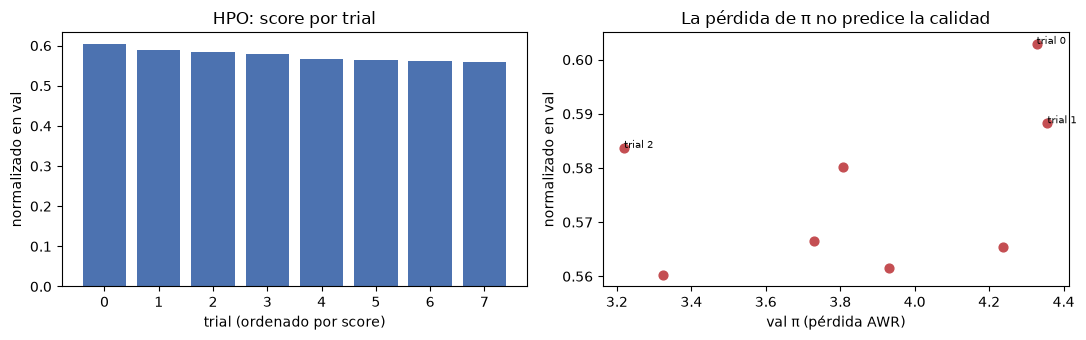

Mejor configuración de arquitectura:


,0
d_model,128.000000
n_heads,4.000000
n_layers,2.000000
dropout,0.000000
lr,0.000538
weight_decay,0.100000
batch_size,512.000000
epochs,10.000000
tau,0.900000
beta,3.000000


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].bar(np.arange(len(hpo)), hpo["score"], color="#4c72b0")
axes[0].set_xlabel("trial (ordenado por score)")
axes[0].set_ylabel("normalizado en val")
axes[0].set_title("HPO: score por trial")

axes[1].scatter(hpo["val_pi"], hpo["score"], s=40, color="#c44e52")
axes[1].set_xlabel("val π (pérdida AWR)")
axes[1].set_ylabel("normalizado en val")
axes[1].set_title("La pérdida de π no predice la calidad")
for idx, row in hpo.head(3).iterrows():
    axes[1].annotate(f"trial {idx}", (row["val_pi"], row["score"]), fontsize=7)
plt.tight_layout()
plt.show()

print("Mejor configuración de arquitectura:")
display(hpo.head(1).T)

## 2. Grilla τ, β y γ sobre la mejor arquitectura

Se entrena una vez por cada combinación de τ ∈ {0,7; 0,9}, β ∈ {3; 10} y γ ∈ {0; 0,9}, con la arquitectura ganadora y `group_dropout=0,3`. Para cada configuración se evalúan **π** y **máximo de Q** en validación (warm-up 0, visible/oculto) con 2 semillas de evaluación.

La configuración final se elige por el **mínimo entre π y Q** (promediado sobre las condiciones), no por las pérdidas ni por el promedio simple. Se reportan además las mejores configuraciones por modo, porque π y Q pueden preferir γ distinto. La tabla y el gráfico por γ muestran qué parte del valor viene de la secuencia (γ=0 vs γ>0).

In [7]:
best = hpo.iloc[0]
integer_keys = {"d_model", "n_heads", "n_layers", "batch_size", "epochs"}
best_model_cfg = {
    key: int(best[key]) if key in integer_keys else float(best[key])
    for key in ["d_model", "n_heads", "n_layers", "dropout", "lr",
                "weight_decay", "batch_size", "epochs"]
}
print("Arquitectura elegida:", best_model_cfg)

grid_rows = []
for tau in GRID_TAU:
    for beta in GRID_BETA:
        for gamma in GRID_GAMMA:
            iql_cfg = {"tau": float(tau), "beta": float(beta), "gamma": float(gamma)}
            start = time.time()
            model, history = train_iql(
                train_ep, val_ep, N_ITEMS,
                seed=0,
                max_batches=MAX_BATCHES,
                device=DEVICE,
                amp=USE_AMP,
                verbose=False,
                **best_model_cfg, **FIXED_TRAIN, **iql_cfg,
            )
            raw = eval_iql(model, hpo_users, HPO_CONDITIONS, seeds=HPO_EVAL_SEEDS)
            summary = summarize(raw, by=["mode", "warmup", "group_visible"])
            norm = summary[("normalized", "mean")]
            pi_score = float(norm.xs("pi", level="mode").mean())
            q_score = float(norm.xs("q", level="mode").mean())
            grid_rows.append({
                **iql_cfg, "pi": pi_score, "q": q_score,
                "score": (pi_score + q_score) / 2,
                "score_robusto": min(pi_score, q_score),
                "val_pi": float(history.iloc[-1]["val_pi"]),
                "minutos": (time.time() - start) / 60,
            })
            print(
                f"tau={tau} beta={beta} gamma={gamma}: "
                f"pi={pi_score:.3f} q={q_score:.3f} "
                f"robusto={grid_rows[-1]['score_robusto']:.3f} "
                f"({grid_rows[-1]['minutos']:.1f} min)"
            )
            del model
            if DEVICE == "cuda":
                torch.cuda.empty_cache()

grid = pd.DataFrame(grid_rows).sort_values("score_robusto", ascending=False).reset_index(drop=True)
grid.to_csv(paths / "grid_iql.csv", index=False)
grid.round(4)

Arquitectura elegida: {'d_model': 128, 'n_heads': 4, 'n_layers': 2, 'dropout': 0.0, 'lr': 0.0005379624172736717, 'weight_decay': 0.1, 'batch_size': 512, 'epochs': 10}
tau=0.7 beta=3.0 gamma=0.0: pi=0.603 q=0.611 robusto=0.603 (1.1 min)
tau=0.7 beta=3.0 gamma=0.9: pi=0.607 q=0.599 robusto=0.599 (1.1 min)
tau=0.7 beta=10.0 gamma=0.0: pi=0.597 q=0.610 robusto=0.597 (1.2 min)
tau=0.7 beta=10.0 gamma=0.9: pi=0.591 q=0.602 robusto=0.591 (1.2 min)
tau=0.9 beta=3.0 gamma=0.0: pi=0.604 q=0.612 robusto=0.604 (1.2 min)
tau=0.9 beta=3.0 gamma=0.9: pi=0.605 q=0.601 robusto=0.601 (1.1 min)
tau=0.9 beta=10.0 gamma=0.0: pi=0.594 q=0.609 robusto=0.594 (1.3 min)
tau=0.9 beta=10.0 gamma=0.9: pi=0.590 q=0.601 robusto=0.590 (1.1 min)


,tau,beta,gamma,pi,q,score,score_robusto,val_pi,minutos
0,0.9,3.0,0.0,0.6044,0.6118,0.6081,0.6044,4.1079,1.2030
1,0.7,3.0,0.0,0.6032,0.6108,0.6070,0.6032,5.9699,1.0953
2,0.9,3.0,0.9,0.6051,0.6008,0.6029,0.6008,4.3277,1.1326
3,0.7,3.0,0.9,0.6073,0.5990,0.6031,0.5990,6.8507,1.0628
4,0.7,10.0,0.0,0.5967,0.6101,0.6034,0.5967,22.7644,1.1841
5,0.9,10.0,0.0,0.5942,0.6094,0.6018,0.5942,5.9970,1.2557
6,0.7,10.0,0.9,0.5908,0.6015,0.5962,0.5908,41.1717,1.1959
7,0.9,10.0,0.9,0.5898,0.6009,0.5953,0.5898,9.9086,1.1462


Configuración IQL elegida (robusta): {'tau': 0.9, 'beta': 3.0, 'gamma': 0.0}
Grilla completa (normalizado medio y robusto):


,tau,beta,gamma,pi,q,score,score_robusto,val_pi,minutos
0,0.9,3.0,0.0,0.604,0.612,0.608,0.604,4.108,1.203
1,0.7,3.0,0.0,0.603,0.611,0.607,0.603,5.970,1.095
2,0.9,3.0,0.9,0.605,0.601,0.603,0.601,4.328,1.133
3,0.7,3.0,0.9,0.607,0.599,0.603,0.599,6.851,1.063
4,0.7,10.0,0.0,0.597,0.610,0.603,0.597,22.764,1.184
5,0.9,10.0,0.0,0.594,0.609,0.602,0.594,5.997,1.256
6,0.7,10.0,0.9,0.591,0.602,0.596,0.591,41.172,1.196
7,0.9,10.0,0.9,0.590,0.601,0.595,0.590,9.909,1.146


Mejor configuración por modo (top 3):
modo pi


,tau,beta,gamma,pi,score,score_robusto
3,0.7,3.0,0.9,0.607,0.603,0.599
2,0.9,3.0,0.9,0.605,0.603,0.601
0,0.9,3.0,0.0,0.604,0.608,0.604


modo q


,tau,beta,gamma,q,score,score_robusto
0,0.9,3.0,0.0,0.612,0.608,0.604
1,0.7,3.0,0.0,0.611,0.607,0.603
4,0.7,10.0,0.0,0.610,0.603,0.597


γ=0 frente a γ>0 (media sobre τ, β y condiciones):


,pi,q,score,score_robusto
gamma,,,,
0.0,0.600,0.611,0.605,0.600
0.9,0.598,0.601,0.599,0.595


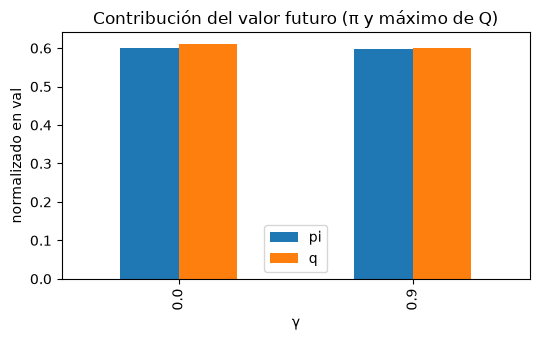

In [8]:
best_grid = grid.iloc[0]
best_iql_cfg = {
    "tau": float(best_grid["tau"]),
    "beta": float(best_grid["beta"]),
    "gamma": float(best_grid["gamma"]),
}
print("Configuración IQL elegida (robusta):", best_iql_cfg)

print("Grilla completa (normalizado medio y robusto):")
display(grid.round(3))

print("Mejor configuración por modo (top 3):")
for mode in ("pi", "q"):
    top = grid.sort_values(mode, ascending=False).head(3)[
        ["tau", "beta", "gamma", mode, "score", "score_robusto"]
    ]
    print(f"modo {mode}")
    display(top.round(3))

gamma_view = grid.groupby("gamma")[["pi", "q", "score", "score_robusto"]].mean()
print("γ=0 frente a γ>0 (media sobre τ, β y condiciones):")
display(gamma_view.round(3))

fig, ax = plt.subplots(figsize=(5.5, 3.5))
gamma_view[["pi", "q"]].plot.bar(ax=ax)
ax.set_xlabel("γ")
ax.set_ylabel("normalizado en val")
ax.set_title("Contribución del valor futuro (π y máximo de Q)")
plt.tight_layout()
plt.show()

## 3. Entrenamiento final con 3 semillas

Se entrena la configuración elegida con 3 semillas. Cada semilla guarda `modelo_iql.pt`, `config.json` e `historial.csv` en `outputs/<RUN_NAME>/final/seed<k>/`. El checkpoint es el de la última época: en IQL las pérdidas de Q y π pueden subir mientras la política mejora.

In [9]:
models, histories = {}, {}
for seed in FINAL_SEEDS:
    model, history = train_iql(
        train_ep, val_ep, N_ITEMS,
        seed=seed,
        max_batches=MAX_BATCHES,
        device=DEVICE,
        amp=USE_AMP,
        output=paths / "final" / f"seed{seed}",
        **best_model_cfg, **FIXED_TRAIN, **best_iql_cfg,
    )
    models[seed] = model
    histories[seed] = history

epoch   1/10 | V 0.0760 Q 0.4842 π 6.0000 | peso medio 0.95 (truncado 0.0%) | val π 4.1539
epoch   2/10 | V 0.0303 Q 0.2467 π 4.0201 | peso medio 0.70 (truncado 0.0%) | val π 4.2141
epoch   3/10 | V 0.0172 Q 0.2201 π 4.0784 | peso medio 0.71 (truncado 0.0%) | val π 5.0450
epoch   4/10 | V 0.0162 Q 0.2115 π 4.1658 | peso medio 0.73 (truncado 0.0%) | val π 3.8619
epoch   5/10 | V 0.0170 Q 0.2077 π 4.1744 | peso medio 0.74 (truncado 0.0%) | val π 4.0645
epoch   6/10 | V 0.0179 Q 0.2043 π 4.1730 | peso medio 0.74 (truncado 0.0%) | val π 4.0969
epoch   7/10 | V 0.0188 Q 0.2016 π 4.1668 | peso medio 0.74 (truncado 0.0%) | val π 4.1162
epoch   8/10 | V 0.0194 Q 0.2001 π 4.1582 | peso medio 0.74 (truncado 0.0%) | val π 4.0560
epoch   9/10 | V 0.0198 Q 0.1986 π 4.1518 | peso medio 0.74 (truncado 0.0%) | val π 4.1317
epoch  10/10 | V 0.0201 Q 0.1977 π 4.1495 | peso medio 0.74 (truncado 0.0%) | val π 4.1079
checkpoint e historial en outputs/iql_gpu_mixto/final/seed0
epoch   1/10 | V 0.0870 Q 0.50

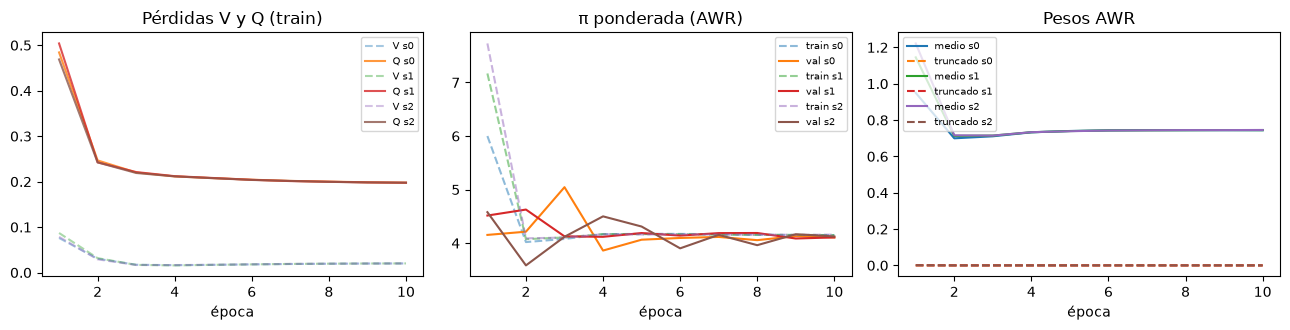

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
for seed, history in histories.items():
    axes[0].plot(history["epoch"], history["train_v"], "--", alpha=0.4, label=f"V s{seed}")
    axes[0].plot(history["epoch"], history["train_q"], "-", alpha=0.8, label=f"Q s{seed}")
    axes[1].plot(history["epoch"], history["train_pi"], "--", alpha=0.5, label=f"train s{seed}")
    axes[1].plot(history["epoch"], history["val_pi"], "-", label=f"val s{seed}")
    axes[2].plot(history["epoch"], history["w_medio"], label=f"medio s{seed}")
    axes[2].plot(history["epoch"], history["w_truncado"], "--", label=f"truncado s{seed}")
axes[0].set_title("Pérdidas V y Q (train)")
axes[1].set_title("π ponderada (AWR)")
axes[2].set_title("Pesos AWR")
for axis in axes:
    axis.set_xlabel("época")
    axis.legend(fontsize=7)
plt.tight_layout()
plt.show()

## 4. Evaluación en validación

Se evalúan π y máximo de Q en las 4 condiciones (warm-up 0/5 × grupo visible/oculto) con las 3 semillas de entrenamiento y 3 semillas de evaluación. Se reportan media, IC 95 % por usuario, hit rate y NDCG@10, más el desvío entre semillas de entrenamiento (separado del IC). También se evalúan las líneas base ajustadas con los mismos logs y, si `LOGS != "random"`, el sistema anterior con ε=0.

In [11]:
conditions = [(0, True), (0, False), (5, True), (5, False)]

frames = []
for seed, model in models.items():
    df = eval_iql(model, final_users, conditions, EVAL_SEEDS)
    df["train_seed"] = seed
    frames.append(df)
val_raw = pd.concat(frames, ignore_index=True)
val_raw.to_csv(paths / "iql_val_sesiones.csv", index=False)

val_summary = summarize(val_raw, by=["mode", "warmup", "group_visible"])
norm = val_summary[("normalized", "mean")]
table = pd.concat({
    "normalized": norm,
    "ci95": val_summary[("normalized", "ci95")],
    "return": val_summary[("return", "mean")],
    "hit_rate": val_summary[("hit_rate", "mean")],
    "ndcg@10": val_summary[("ndcg@10", "mean")],
    "precision@10": val_summary[("precision@10", "mean")],
}, axis=1)
print("Validación: media e IC 95 % por usuario")
display(table.round(3))
table.to_csv(paths / "iql_val_resumen.csv")

seed_stats = (
    val_raw.groupby(["mode", "warmup", "group_visible", "train_seed"])["normalized"].mean()
    .groupby(["mode", "warmup", "group_visible"]).agg(["mean", "std"]).round(3)
)
print("Media y desvío entre semillas de entrenamiento")
display(seed_stats)
seed_stats.to_csv(paths / "iql_val_semillas.csv")

Validación: media e IC 95 % por usuario


normalized   ci95  return  hit_rate  ndcg@10  \
mode warmup group_visible                                                 
pi   0      False               0.558  0.014  80.630     0.750    0.845   
            True                0.648  0.011  83.299     0.798    0.880   
     5      False               0.583  0.014  61.587     0.775    0.841   
            True                0.658  0.012  63.321     0.818    0.877   
q    0      False               0.566  0.013  80.830     0.753    0.818   
            True                0.651  0.011  83.302     0.798    0.875   
     5      False               0.588  0.013  61.734     0.777    0.838   
            True                0.659  0.011  63.316     0.818    0.876   

                           precision@10  
mode warmup group_visible                
pi   0      False                 0.817  
            True                  0.855  
     5      False                 0.810  
            True                  0.850  
q    0      False                 0.794  
            True                  0.852  
     5      False                 0.810  
            True                  0.850

Media y desvío entre semillas de entrenamiento


mean    std
mode warmup group_visible              
pi   0      False          0.558  0.000
            True           0.648  0.001
     5      False          0.583  0.001
            True           0.658  0.002
q    0      False          0.566  0.007
            True           0.651  0.002
     5      False          0.588  0.004
            True           0.659  0.001

In [12]:
factories = baseline_factories(baseline_train, N_ITEMS)
if LOGS != "random":
    _, temperature = PRESETS[LOGS]
    factories["sistema_anterior_eps0"] = lambda: PreviousSystem.fit(
        train, N_ITEMS, 0.0, temperature, np.random.default_rng(0)
    )

base_frames = []
for name, factory in factories.items():
    df = eval_policy(factory(), final_users, conditions, EVAL_SEEDS)
    df["policy"] = name
    base_frames.append(df)
base_raw = pd.concat(base_frames, ignore_index=True)
base_raw.to_csv(paths / "iql_baselines_val_sesiones.csv", index=False)

base_summary = summarize(base_raw, by=["policy", "warmup", "group_visible"])
base_summary.to_csv(paths / "iql_baselines_val_resumen.csv")
base_norm = base_summary[("normalized", "mean")]

comparison = base_norm.unstack(["warmup", "group_visible"])
for mode in ("pi", "q"):
    comparison.loc[f"iql_{mode}"] = norm.xs(mode, level="mode")
comparison.to_csv(paths / "comparacion_val.csv")
print("Comparación en validación (normalizado, 0=azar, 1=oráculo):")
display(comparison.round(3))

Comparación en validación (normalizado, 0=azar, 1=oráculo):


warmup                     0             5       
group_visible          False  True   False  True 
policy                                           
group_mean             0.553  0.653  0.566  0.664
group_posterior        0.618  0.653  0.639  0.664
item_mean              0.553  0.553  0.566  0.566
popularity             0.559  0.559  0.574  0.574
random                 0.009  0.005 -0.006 -0.005
sistema_anterior_eps0  0.491  0.581  0.490  0.579
iql_pi                 0.558  0.648  0.583  0.658
iql_q                  0.566  0.651  0.588  0.659

In [13]:
per_group = summarize(
    val_raw, by=["mode", "warmup", "group_visible", "group"]
)[("normalized", "mean")]
per_group_table = per_group.unstack("group")
per_group_table.to_csv(paths / "iql_val_por_grupo.csv")
print("Resultados por grupo (normalizado):")
display(per_group_table.round(3))

Resultados por grupo (normalizado):


group                          0      1      2      3      4      5      6  \
mode warmup group_visible                                                    
pi   0      False          0.649  0.599  0.582  0.497  0.574  0.431  0.585   
            True           0.686  0.678  0.625  0.595  0.673  0.682  0.688   
     5      False          0.665  0.613  0.572  0.498  0.638  0.529  0.592   
            True           0.712  0.684  0.627  0.581  0.691  0.697  0.693   
q    0      False          0.645  0.611  0.553  0.518  0.597  0.490  0.563   
            True           0.677  0.678  0.614  0.612  0.680  0.694  0.681   
     5      False          0.664  0.612  0.559  0.514  0.632  0.558  0.594   
            True           0.701  0.691  0.626  0.591  0.683  0.700  0.687   

group                          7  
mode warmup group_visible         
pi   0      False          0.543  
            True           0.555  
     5      False          0.557  
            True           0.578  
q    0      False          0.555  
            True           0.573  
     5      False          0.571  
            True           0.595

## 5. Test reservado

`RUN_TEST = False` por defecto: test se usa **una sola vez**, cuando la configuración, γ, τ, β y las semillas ya están congelados en validación. Al ponerlo en `True`, evalúa las 3 semillas de entrenamiento (π y máximo de Q) y las líneas base con los mismos logs, y escribe `sesiones.csv`, `resumen.csv` y `resumen_por_grupo.csv`.

In [14]:
if RUN_TEST:
    test_users = load_test(DATASET)
    test_frames = []
    for seed, model in models.items():
        df = eval_iql(model, test_users, conditions, EVAL_SEEDS)
        df["policy"] = df["mode"].map(lambda mode: f"iql_{mode}_seed{seed}")
        test_frames.append(df)
    for name, factory in factories.items():
        df = eval_policy(factory(), test_users, conditions, EVAL_SEEDS)
        df["policy"] = name
        test_frames.append(df)
    test_raw = pd.concat(test_frames, ignore_index=True)
    write_reports(test_raw, paths / "eval" / "test")
else:
    print("RUN_TEST=False: test reservado. Cambiarlo a True una sola vez, al final.")

RUN_TEST=False: test reservado. Cambiarlo a True una sola vez, al final.


## Checklist antes de la entrega

- [ ] La arquitectura y τ, β, γ se eligieron **sólo con validación**.
- [ ] Se reportan 3 semillas de entrenamiento: media y desvío entre semillas, separados del IC 95 % por usuario.
- [ ] Las líneas base se ajustaron con los **mismos logs** que el modelo.
- [ ] Están las dos políticas: π (AWR) y máximo de Q, con la comparación γ=0 vs γ>0.
- [ ] Están los resultados por grupo y las métricas secundarias (hit rate, NDCG@10).
- [ ] Si se usa `mixto`, se repitió todo con `LOGS = "mixto"` y se reajustaron las líneas base con esos logs.
- [ ] `RUN_TEST = True` se usó una sola vez, al final.